<a href="https://colab.research.google.com/github/eyramana/MLA0201-FUNDAMENTALS-OF-MACHINE-LEARNING/blob/main/Ramana_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Initial Hypothesis: ['0', '0', '0', '0', '0', '0']
After Example 1: ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After Example 2: ['Sunny', 'Warm', 'Any', 'Strong', 'Warm', 'Same']
After Example 4: ['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']

Final Most Specific Hypothesis:
['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']


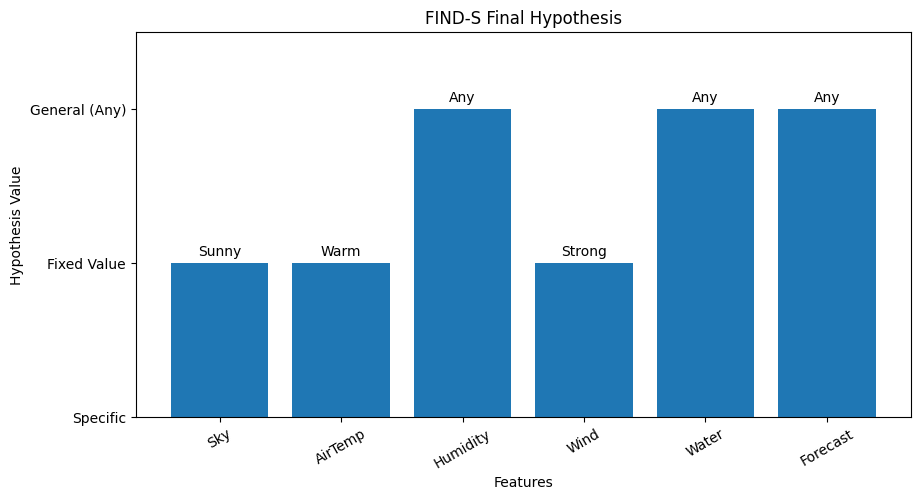

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# FIND-S algorithm (using 'Any' instead of '?')
hypothesis = ['0'] * 6

print("\nInitial Hypothesis:", hypothesis)

for index, row in df.iterrows():
    # Consider only positive examples
    if row['EnjoySport'] == 'Yes':
        for i in range(6):
            if hypothesis[i] == '0':
                hypothesis[i] = row.iloc[i]
            elif hypothesis[i] != row.iloc[i]:
                hypothesis[i] = 'Any'
        print(f"After Example {index + 1}: {hypothesis}")

print("\nFinal Most Specific Hypothesis:")
print(hypothesis)

# -----------------------------
# Matplotlib Visualization
# -----------------------------

features = ['Sky', 'AirTemp', 'Humidity',
            'Wind', 'Water', 'Forecast']

# Convert hypothesis into numeric values for visualization
values = []
for h in hypothesis:
    if h == 'Any':
        values.append(2)
    elif h == '0':
        values.append(0)
    else:
        values.append(1)

plt.figure(figsize=(10, 5))
bars = plt.bar(features, values)

plt.title("FIND-S Final Hypothesis")
plt.xlabel("Features")
plt.ylabel("Hypothesis Value")
plt.xticks(rotation=30)

# Add labels
for bar, h in zip(bars, hypothesis):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        h,
        ha='center'
    )

plt.yticks([0, 1, 2], ['Specific', 'Fixed Value', 'General (Any)'])
plt.ylim(0, 2.5)
plt.show()

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Final Specific Boundary (S):
['Sunny', 'Warm', 'Any', 'Strong', 'Any', 'Any']

Final General Boundary (G):
['Sunny', 'Any', 'Any', 'Any', 'Any', 'Any']
['Any', 'Warm', 'Any', 'Any', 'Any', 'Any']
['Any', 'Any', 'Any', 'Strong', 'Any', 'Any']


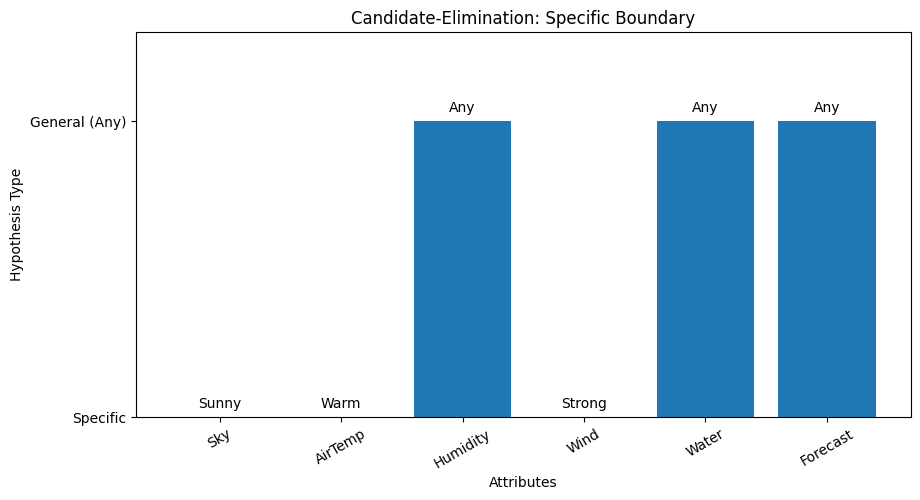

In [ ]:
# Candidate-Elimination Algorithm
# Google Colab

import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Create training data and save it as CSV
# -------------------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save as CSV
df.to_csv('enjoysport.csv', index=False)

# Read CSV file
df = pd.read_csv('enjoysport.csv')

print("Training Data:")
print(df)


# -------------------------------------------------
# 2. Candidate-Elimination Algorithm
# -------------------------------------------------

def candidate_elimination(data):

    attributes = list(data.columns[:-1])
    target = data.columns[-1]

    # Most specific hypothesis
    S = ['0'] * len(attributes)

    # Most general hypothesis (using 'Any' instead of '?')
    G = [['Any'] * len(attributes)]

    for _, example in data.iterrows():

        x = list(example[:-1])
        label = example[target]

        # -----------------------------------------
        # Positive Example
        # -----------------------------------------
        if label == 'Yes':

            # Remove inconsistent hypotheses from G
            G = [
                g for g in G
                if all(g[i] == 'Any' or g[i] == x[i] for i in range(len(x)))
            ]

            # Generalize S
            for i in range(len(x)):

                if S[i] == '0':
                    S[i] = x[i]

                elif S[i] != x[i]:
                    S[i] = 'Any'

            # Remove G hypotheses that are less general than S
            G = [
                g for g in G
                if all(g[i] == 'Any' or S[i] == 'Any' or g[i] == S[i]
                       for i in range(len(x)))
            ]

        # -----------------------------------------
        # Negative Example
        # -----------------------------------------
        else:

            new_G = []

            for g in G:

                # If G covers the negative example,
                # specialize it
                if all(g[i] == 'Any' or g[i] == x[i]
                       for i in range(len(x))):

                    for i in range(len(x)):

                        if g[i] == 'Any':
                            new_h = g.copy()

                            if S[i] != 'Any' and S[i] != '0':
                                new_h[i] = S[i]

                                if new_h not in new_G:
                                    new_G.append(new_h)

                else:
                    new_G.append(g)

            G = new_G

    return S, G


# -------------------------------------------------
# 3. Run Algorithm
# -------------------------------------------------

S, G = candidate_elimination(df)

print("\nFinal Specific Boundary (S):")
print(S)

print("\nFinal General Boundary (G):")

for g in G:
    print(g)


# -------------------------------------------------
# 4. Matplotlib Visualization
# -------------------------------------------------

features = list(df.columns[:-1])

# Convert hypothesis values to numbers
# 0 = specific value
# 1 = Any
values = []

for value in S:
    if value == 'Any':
        values.append(1)
    else:
        values.append(0)

plt.figure(figsize=(10, 5))

bars = plt.bar(features, values)

plt.title("Candidate-Elimination: Specific Boundary")
plt.xlabel("Attributes")
plt.ylabel("Hypothesis Type")

plt.xticks(rotation=30)
plt.yticks([0, 1], ['Specific', 'General (Any)'])

# Display hypothesis values on bars
for bar, value in zip(bars, S):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.03,
        value,
        ha='center'
    )

plt.ylim(0, 1.3)
plt.show()

### ID3 Decision Tree Algorithm Implementation
In this section, we implement the ID3 algorithm from scratch to construct a decision tree based on Information Gain (using Entropy) and classify a new test sample.

Training Data:

     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Initial Hypothesis:
['0', '0', '0', '0', '0', '0']
After Example 1 : ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
After Example 2 : ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
After Example 4 : ['Sunny', 'Warm', '?', 'Strong', '?', '?']

Final Most Specific Hypothesis:
['Sunny', 'Warm', '?', 'Strong', '?', '?']


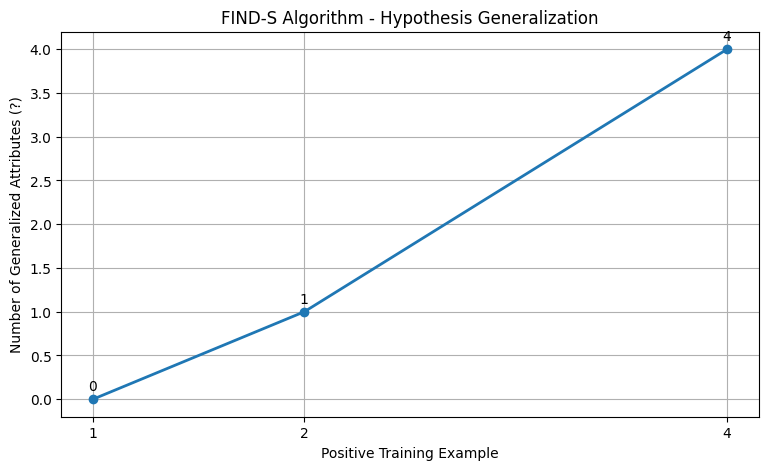

In [ ]:
# EXPERIMENT 3: FIND-S ALGORITHM WITH GRAPH

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Training Dataset
# -----------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:\n")
print(df)


# -----------------------------------------
# 2. FIND-S Algorithm
# -----------------------------------------

features = list(df.columns[:-1])

# Initial most specific hypothesis
hypothesis = ['0'] * len(features)

# Store number of generalizations
steps = []
generalized_count = []

print("\nInitial Hypothesis:")
print(hypothesis)

count = 0

for index, row in df.iterrows():

    # Only positive examples are considered
    if row['EnjoySport'] == 'Yes':

        for i in range(len(features)):

            if hypothesis[i] == '0':
                hypothesis[i] = row[features[i]]

            elif hypothesis[i] != row[features[i]]:
                hypothesis[i] = '?'

        count += hypothesis.count('?')

        steps.append(index + 1)
        generalized_count.append(count)

        print(
            "After Example", index + 1,
            ":", hypothesis
        )


# -----------------------------------------
# 3. Final Hypothesis
# -----------------------------------------

print("\nFinal Most Specific Hypothesis:")
print(hypothesis)


# -----------------------------------------
# 4. Graph
# -----------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    generalized_count,
    marker='o',
    linewidth=2
)

plt.title("FIND-S Algorithm - Hypothesis Generalization")
plt.xlabel("Positive Training Example")
plt.ylabel("Number of Generalized Attributes (?)")

plt.xticks(steps)

plt.grid(True)

# Display values
for x, y in zip(steps, generalized_count):
    plt.text(x, y + 0.1, str(y), ha='center')

plt.show()

Training Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No

Generated ID3 Decision Tree:
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}

New Unseen Sampl

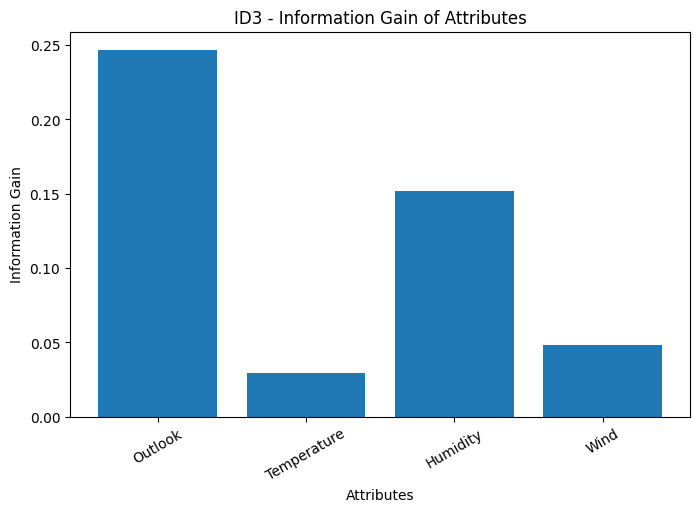

In [ ]:
# ID3 Decision Tree - Complete Google Colab Code

import pandas as pd
import matplotlib.pyplot as plt
from math import log2

# --------------------------------------------------
# 1. Create Dataset
# --------------------------------------------------

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
                'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
                    'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
             'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],

    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes',
                   'Yes', 'No']
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)


# --------------------------------------------------
# 2. Entropy Function
# --------------------------------------------------

def entropy(data):

    target = data.iloc[:, -1]
    values = target.value_counts()

    total = len(target)
    result = 0

    for count in values:
        probability = count / total
        result -= probability * log2(probability)

    return result


# --------------------------------------------------
# 3. Information Gain
# --------------------------------------------------

def information_gain(data, attribute):

    total_entropy = entropy(data)

    values = data[attribute].unique()
    weighted_entropy = 0

    for value in values:

        subset = data[data[attribute] == value]

        weighted_entropy += (
            len(subset) / len(data)
        ) * entropy(subset)

    return total_entropy - weighted_entropy


# --------------------------------------------------
# 4. ID3 Algorithm
# --------------------------------------------------

def ID3(data, original_data, features):

    # If all examples belong to the same class
    if len(data.iloc[:, -1].unique()) == 1:
        return data.iloc[:, -1].iloc[0]

    # If no features remain
    if len(features) == 0:
        return original_data.iloc[:, -1].mode()[0]

    # Calculate information gain
    gains = {}

    for feature in features:
        gains[feature] = information_gain(data, feature)

    # Select feature with maximum information gain
    best_feature = max(gains, key=gains.get)

    tree = {best_feature: {}}

    remaining_features = [
        feature for feature in features
        if feature != best_feature
    ]

    # Create branches
    for value in data[best_feature].unique():

        subset = data[data[best_feature] == value]

        tree[best_feature][value] = ID3(
            subset,
            original_data,
            remaining_features
        )

    return tree


# --------------------------------------------------
# 5. Build Decision Tree
# --------------------------------------------------

features = list(df.columns[:-1])

tree = ID3(df, df, features)

print("\nGenerated ID3 Decision Tree:")
print(tree)


# --------------------------------------------------
# 6. Prediction Function
# --------------------------------------------------

def predict(query, tree, default='Yes'):

    for key in query.keys():

        if key in tree:

            try:
                result = tree[key][query[key]]

            except KeyError:
                return default

            if isinstance(result, dict):
                return predict(query, result, default)

            else:
                return result

    return default


# --------------------------------------------------
# 7. New Sample
# --------------------------------------------------

new_sample = {
    'Outlook': 'Rain',
    'Temperature': 'Cool',
    'Humidity': 'Normal',
    'Wind': 'Strong'
}

prediction = predict(new_sample, tree)

print("\nNew Unseen Sample:")
print(new_sample)

print("\nPredicted Class (PlayTennis):", prediction)


# --------------------------------------------------
# 8. Matplotlib Visualization
# --------------------------------------------------

# Show Information Gain of each attribute

gain_values = []

for feature in features:
    gain_values.append(information_gain(df, feature))

plt.figure(figsize=(8, 5))

plt.bar(features, gain_values)

plt.title("ID3 - Information Gain of Attributes")
plt.xlabel("Attributes")
plt.ylabel("Information Gain")

plt.xticks(rotation=30)

plt.show()

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Final Most Specific Hypothesis:
Sky : Sunny
AirTemp : Warm
Humidity : Any Value
Wind : Strong
Water : Any Value
Forecast : Any Value


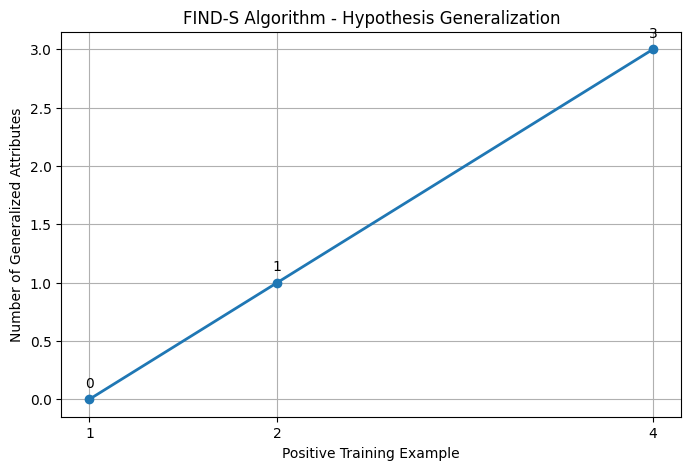

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Training data
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# FIND-S Algorithm
features = list(df.columns[:-1])
hypothesis = ['0'] * len(features)

steps = []
generalized_count = []

for i, row in df.iterrows():

    # Consider only positive examples
    if row['EnjoySport'] == 'Yes':

        if hypothesis == ['0'] * len(features):
            hypothesis = [row[feature] for feature in features]

        else:
            for j, feature in enumerate(features):
                if hypothesis[j] != row[feature]:
                    hypothesis[j] = 'Any Value'

        steps.append(i + 1)
        generalized_count.append(
            hypothesis.count('Any Value')
        )

# Display result
print("Training Data:")
print(df)

print("\nFinal Most Specific Hypothesis:")
for feature, value in zip(features, hypothesis):
    print(feature, ":", value)

# Graph
plt.figure(figsize=(8, 5))

plt.plot(
    steps,
    generalized_count,
    marker='o',
    linewidth=2
)

plt.title("FIND-S Algorithm - Hypothesis Generalization")
plt.xlabel("Positive Training Example")
plt.ylabel("Number of Generalized Attributes")

plt.xticks(steps)
plt.grid(True)

for x, y in zip(steps, generalized_count):
    plt.text(x, y + 0.1, str(y), ha='center')

plt.show()